# Assignment 8 — Image Denoising: Direct vs. Residual Learning

We draw, implement, train and evaluate **six** deep denoising models and compare two learning
strategies — **direct learning** (predict the clean image) and **residual learning** (predict the
noise, then subtract it).

| # | Model | Architecture family | Learning type | Target |
|---|---|---|---|---|
| 1 | **DAE** | plain conv encoder–decoder (no skips) | direct | clean $x$ |
| 2 | **RED-Net** | conv–deconv with **additive** skips | direct | clean $x$ |
| 3 | **U-Net** | encoder–decoder with **concatenation** skips | direct | clean $x$ |
| 4 | **DnCNN** | plain deep CNN + BatchNorm | **residual** | noise $n=y-x$ |
| 5 | **Model1** (proposed) | ProposedNet (res-blocks + channel attention) | direct | clean $x$ |
| 6 | **Model2** (proposed) | **the same** ProposedNet | **residual** | noise $n=y-x$ |

**Why Model1 and Model2 share one architecture.** The assignment stresses that *architecture*
(RED-Net vs U-Net vs DnCNN) and *learning target* (direct vs residual) are different things. By
giving Model1 and Model2 an **identical** network and changing **only the target**, Experiment 2
isolates the effect of direct vs residual learning with everything else held fixed.

**Setup:** RGB (colour) images, Gaussian noise. Models are trained **blind** on random
$\sigma\in[5,55]$ and tested at $\sigma=15,25,50$. Same data, same split, same training recipe for
all six models.

| Report piece | Where |
|---|---|
| Dataset + noise + splits | §2 |
| Architecture drawings | §3 |
| Model implementations | §4 |
| Training (same conditions) | §5 |
| Evaluation (MSE / PSNR / SSIM) | §6 |
| Exp. 1 model comparison | §7 |
| Exp. 2 direct vs residual | §8 |
| Exp. 3 noise levels | §9 |
| Exp. 4 visual comparison | §10 |
| Results + complexity tables | §11 |
| Discussion (15 questions) | §12 |

## 0. Environment

In [1]:
%pip install -q torch torchvision "torchmetrics[image]" matplotlib pandas pillow tqdm numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports and configuration

In [2]:
import os, gc, json, time, math, random
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.backends.cuda.matmul.allow_tf32 = True

@dataclass
class CFG:
    # data
    div2k_train: str = "../02/data/DIV2K_train_HR"
    div2k_valid: str = "../02/data/DIV2K_valid_HR"
    test_dir:    str = "test images"
    n_train_images: int = 400        # DIV2K images used to build the patch pool
    patches_per_image: int = 40
    patch: int = 64
    val_images: int = 8
    val_size: int = 256
    test_size: int = 512

    # noise (Gaussian, on the 0-255 scale)
    sigma_train_min: float = 5.0
    sigma_train_max: float = 55.0
    sigmas_test: tuple = (15.0, 25.0, 50.0)

    # training (identical for every model)
    iters: int = 10000
    batch: int = 16
    lr: float = 1e-3          # identical for every model (He init + clipping keep DnCNN stable)
    grad_clip: float = 1.0
    val_every: int = 500
    seed: int = 42
    quick_mode: bool = True

CFG = CFG()
if CFG.quick_mode:
    CFG.iters = 6000

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
use_cuda = device == "cuda"

OUT = Path("outputs")
FIG, RES, DEN, CACHE = OUT/"figures", OUT/"results", OUT/"denoised", Path("cache")
for d in (FIG, RES, DEN, CACHE): d.mkdir(parents=True, exist_ok=True)

print(f"device={device}  gpu={torch.cuda.get_device_name(0) if use_cuda else 'cpu'}")
print("config:", json.dumps(asdict(CFG), indent=2))

device=cuda  gpu=NVIDIA GeForce RTX 5070 Ti
config: {
  "div2k_train": "../02/data/DIV2K_train_HR",
  "div2k_valid": "../02/data/DIV2K_valid_HR",
  "test_dir": "test images",
  "n_train_images": 400,
  "patches_per_image": 40,
  "patch": 64,
  "val_images": 8,
  "val_size": 256,
  "test_size": 512,
  "sigma_train_min": 5.0,
  "sigma_train_max": 55.0,
  "sigmas_test": [
    15.0,
    25.0,
    50.0
  ],
  "iters": 6000,
  "batch": 16,
  "lr": 0.001,
  "grad_clip": 1.0,
  "val_every": 500,
  "seed": 42,
  "quick_mode": true
}


## 2. Dataset, noise model and splits

**Clean images.** We use **DIV2K** (high-quality 2K photographs) as the clean-image source, and our
own **10 test photographs** (`test images/`) as the held-out test set.

| Split | Source | Amount | Used for |
|---|---|---|---|
| **Train** | `DIV2K_train_HR` | 400 images → 16,000 random $64\times64$ **colour** patches | training all six models |
| **Validation** | `DIV2K_valid_HR` | 8 images, $256\times256$ centre crops | monitoring PSNR during training |
| **Test** | `test images/` (our photos) | 10 images, $512\times512$ | all reported metrics |

The **same data and the same split are used for all six models**.

**Noise model.** Additive white Gaussian noise: $y = x + n,\; n\sim\mathcal N(0,\sigma^2)$ with
$\sigma$ on the 0–255 scale. During training $\sigma$ is drawn randomly from $[5,55]$ for every
sample (**blind denoising**), so a single trained model can be tested at $\sigma=15,25,50$.

loaded cached patches: (16000, 64, 64, 3)


train patches (16000, 64, 64, 3) | val torch.Size([8, 3, 256, 256]) | test torch.Size([10, 3, 512, 512])


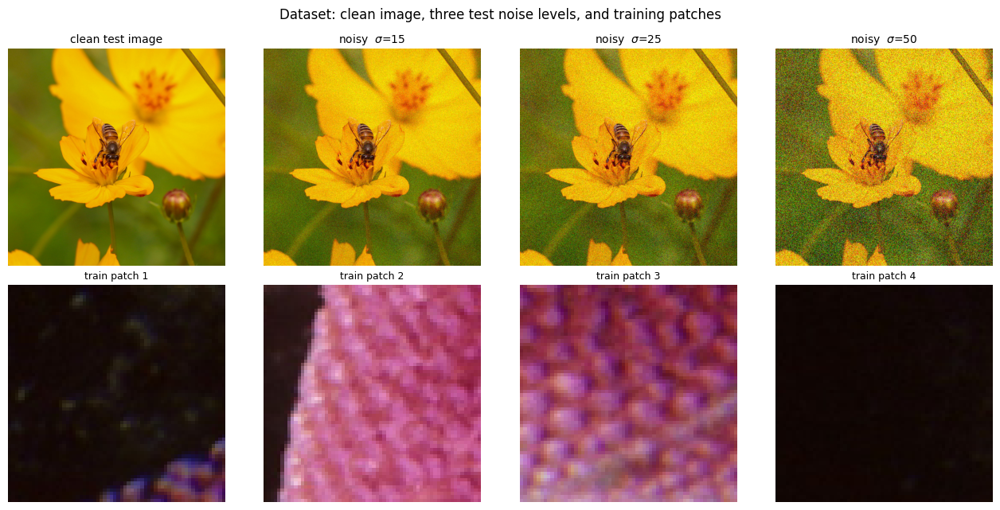

In [3]:
def to_float(a):   return a.astype(np.float32)/255.0
def load_rgb(p):   return Image.open(p).convert("RGB")

def center_square(img, size):
    return ImageOps.fit(img, (size, size), Image.LANCZOS)

# ---------- training patches (cached) ----------
cache_file = CACHE/f"div2k_patches_{CFG.n_train_images}x{CFG.patches_per_image}_{CFG.patch}.npy"
if cache_file.exists():
    patches = np.load(cache_file)
    print("loaded cached patches:", patches.shape)
else:
    rng = np.random.default_rng(CFG.seed)
    paths = sorted(Path(CFG.div2k_train).glob("*.png"))[:CFG.n_train_images]
    assert paths, f"no DIV2K images found in {CFG.div2k_train}"
    buf = []
    for p in tqdm(paths, desc="extracting patches"):
        a = np.array(load_rgb(p))
        H, W = a.shape[:2]
        for _ in range(CFG.patches_per_image):
            i = rng.integers(0, H-CFG.patch); j = rng.integers(0, W-CFG.patch)
            buf.append(a[i:i+CFG.patch, j:j+CFG.patch])
    patches = np.stack(buf).astype(np.uint8)
    np.save(cache_file, patches)
    print("patches:", patches.shape, "->", cache_file)

# ---------- validation images ----------
val_paths = sorted(Path(CFG.div2k_valid).glob("*.png"))[:CFG.val_images]
val_clean = np.stack([np.array(center_square(load_rgb(p), CFG.val_size)) for p in val_paths])
val_t = torch.from_numpy(to_float(val_clean)).permute(0,3,1,2).to(device)

# ---------- test images (our own photos) ----------
test_paths = sorted([p for p in Path(CFG.test_dir).iterdir()
                     if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}])
test_clean = np.stack([np.array(center_square(load_rgb(p), CFG.test_size)) for p in test_paths])
test_t = torch.from_numpy(to_float(test_clean)).permute(0,3,1,2).to(device)
print(f"train patches {patches.shape} | val {val_t.shape} | test {test_t.shape}")

def add_noise(x, sigma):
    # x: float tensor in [0,1]; sigma on the 0-255 scale (scalar or per-sample tensor)
    if not torch.is_tensor(sigma):
        sigma = torch.full((x.shape[0],1,1,1), float(sigma), device=x.device)
    return x + torch.randn_like(x) * (sigma/255.0)

def sample_batch(bs):
    idx = np.random.randint(0, patches.shape[0], bs)
    x = torch.from_numpy(to_float(patches[idx])).permute(0,3,1,2).to(device)
    sig = torch.empty(bs,1,1,1, device=device).uniform_(CFG.sigma_train_min, CFG.sigma_train_max)
    return x, add_noise(x, sig)

# visualise the data + noise levels
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
x0 = test_t[:1]
axes[0,0].imshow(test_clean[0]); axes[0,0].set_title("clean test image", fontsize=10)
for k, s in enumerate(CFG.sigmas_test):
    y = add_noise(x0, s).clamp(0,1)[0].permute(1,2,0).cpu().numpy()
    axes[0,k+1].imshow(y); axes[0,k+1].set_title(f"noisy  $\\sigma$={int(s)}", fontsize=10)
for k in range(4):
    axes[1,k].imshow(patches[k]); axes[1,k].set_title(f"train patch {k+1}", fontsize=9)
for a in axes.reshape(-1): a.axis("off")
fig.suptitle("Dataset: clean image, three test noise levels, and training patches")
fig.tight_layout(); fig.savefig(FIG/"d_dataset.png", dpi=130, bbox_inches="tight"); plt.show()

## 3. Architecture drawings

The assignment asks us to **draw** each architecture. Below, every model is drawn as a block
diagram: boxes are layers/stages, black arrows are the forward path, **red arcs are additive skip
connections** and **blue arcs are concatenation skip connections**.

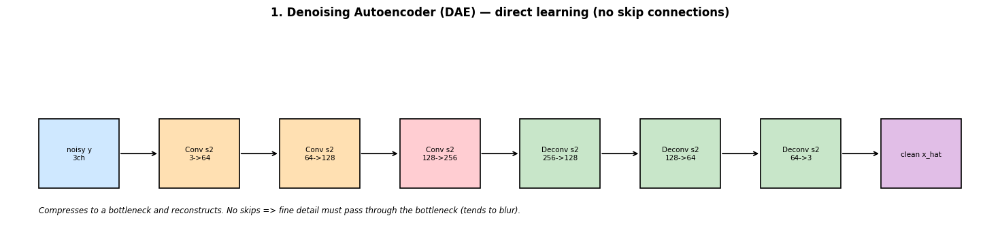

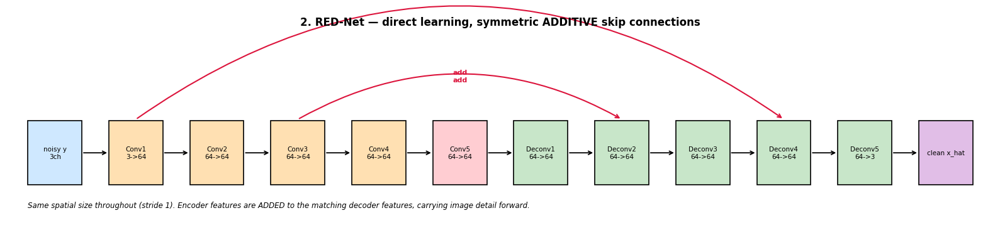

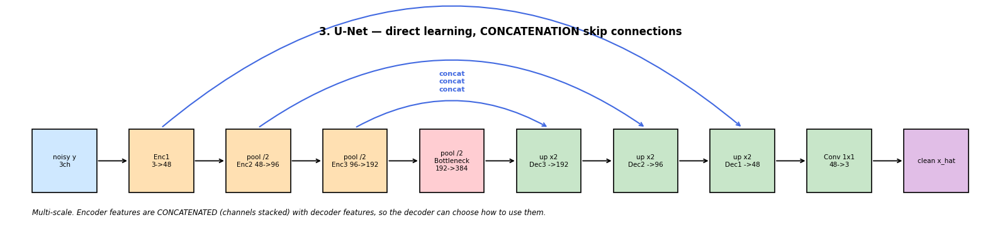

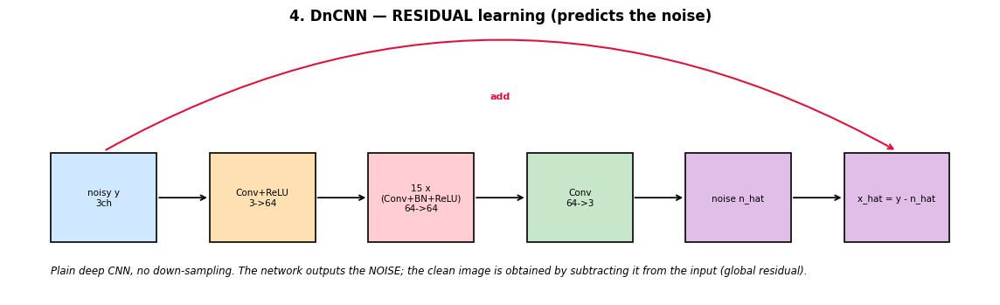

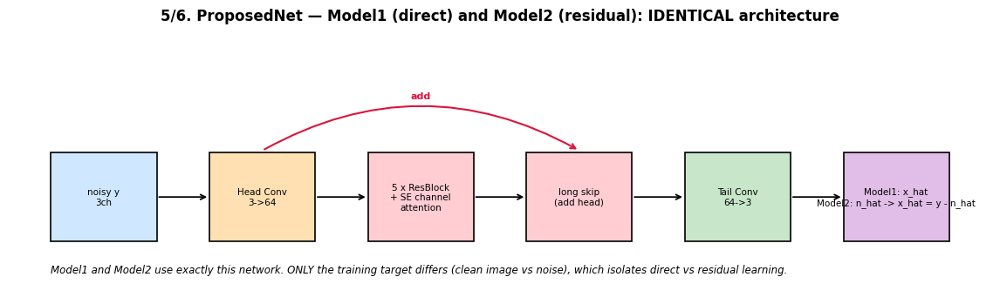

In [4]:
def draw_arch(title, blocks, skips=(), fname=None, note="", figsize=None):
    n = len(blocks); w, gap = 1.0, 0.5
    figsize = figsize or (min(16, 1.6*n + 2), 3.6)
    fig, ax = plt.subplots(figsize=figsize)
    xs = []
    for i, (label, color) in enumerate(blocks):
        x = i*(w+gap); xs.append(x)
        ax.add_patch(Rectangle((x,0), w, 1, facecolor=color, edgecolor="black", lw=1.2))
        ax.text(x+w/2, 0.5, label, ha="center", va="center", fontsize=7.5)
        if i < n-1:
            ax.annotate("", xy=(x+w+gap, 0.5), xytext=(x+w, 0.5),
                        arrowprops=dict(arrowstyle="->", lw=1.3))
    for k, (i, j, kind) in enumerate(skips):
        x1, x2 = xs[i]+w/2, xs[j]+w/2
        col = "crimson" if kind == "add" else "royalblue"
        h = 1.05 + 0.12*k
        ax.annotate("", xy=(x2, 1.02), xytext=(x1, 1.02),
                    arrowprops=dict(arrowstyle="->", lw=1.5, color=col,
                                    connectionstyle=f"arc3,rad=-{0.28+0.07*k}"))
        ax.text((x1+x2)/2, h+0.55, "add" if kind=="add" else "concat",
                ha="center", fontsize=8, color=col, fontweight="bold")
    if note: ax.text(0, -0.35, note, fontsize=8.5, style="italic")
    ax.set_xlim(-0.4, xs[-1]+w+0.4); ax.set_ylim(-0.6, 2.4); ax.axis("off")
    ax.set_title(title, fontsize=12, fontweight="bold")
    fig.tight_layout()
    if fname: fig.savefig(FIG/fname, dpi=130, bbox_inches="tight")
    plt.show()

C_IN, C_ENC, C_BOT, C_DEC, C_OUT = "#cfe8ff", "#ffe0b2", "#ffcdd2", "#c8e6c9", "#e1bee7"

draw_arch("1. Denoising Autoencoder (DAE) — direct learning (no skip connections)",
  [("noisy y\n3ch",C_IN),("Conv s2\n3->64",C_ENC),("Conv s2\n64->128",C_ENC),
   ("Conv s2\n128->256",C_BOT),("Deconv s2\n256->128",C_DEC),("Deconv s2\n128->64",C_DEC),
   ("Deconv s2\n64->3",C_DEC),("clean x_hat",C_OUT)],
  note="Compresses to a bottleneck and reconstructs. No skips => fine detail must pass through the bottleneck (tends to blur).",
  fname="arch_dae.png")

draw_arch("2. RED-Net — direct learning, symmetric ADDITIVE skip connections",
  [("noisy y\n3ch",C_IN),("Conv1\n3->64",C_ENC),("Conv2\n64->64",C_ENC),("Conv3\n64->64",C_ENC),
   ("Conv4\n64->64",C_ENC),("Conv5\n64->64",C_BOT),("Deconv1\n64->64",C_DEC),("Deconv2\n64->64",C_DEC),
   ("Deconv3\n64->64",C_DEC),("Deconv4\n64->64",C_DEC),("Deconv5\n64->3",C_DEC),("clean x_hat",C_OUT)],
  skips=[(3,7,"add"),(1,9,"add")],
  note="Same spatial size throughout (stride 1). Encoder features are ADDED to the matching decoder features, carrying image detail forward.",
  fname="arch_rednet.png")

draw_arch("3. U-Net — direct learning, CONCATENATION skip connections",
  [("noisy y\n3ch",C_IN),("Enc1\n3->48",C_ENC),("pool /2\nEnc2 48->96",C_ENC),
   ("pool /2\nEnc3 96->192",C_ENC),("pool /2\nBottleneck\n192->384",C_BOT),
   ("up x2\nDec3 ->192",C_DEC),("up x2\nDec2 ->96",C_DEC),("up x2\nDec1 ->48",C_DEC),
   ("Conv 1x1\n48->3",C_DEC),("clean x_hat",C_OUT)],
  skips=[(3,5,"concat"),(2,6,"concat"),(1,7,"concat")],
  note="Multi-scale. Encoder features are CONCATENATED (channels stacked) with decoder features, so the decoder can choose how to use them.",
  fname="arch_unet.png")

draw_arch("4. DnCNN — RESIDUAL learning (predicts the noise)",
  [("noisy y\n3ch",C_IN),("Conv+ReLU\n3->64",C_ENC),("15 x\n(Conv+BN+ReLU)\n64->64",C_BOT),
   ("Conv\n64->3",C_DEC),("noise n_hat",C_OUT),("x_hat = y - n_hat",C_OUT)],
  skips=[(0,5,"add")],
  note="Plain deep CNN, no down-sampling. The network outputs the NOISE; the clean image is obtained by subtracting it from the input (global residual).",
  fname="arch_dncnn.png")

draw_arch("5/6. ProposedNet — Model1 (direct) and Model2 (residual): IDENTICAL architecture",
  [("noisy y\n3ch",C_IN),("Head Conv\n3->64",C_ENC),("5 x ResBlock\n+ SE channel\nattention",C_BOT),
   ("long skip\n(add head)",C_BOT),("Tail Conv\n64->3",C_DEC),
   ("Model1: x_hat\nModel2: n_hat -> x_hat = y - n_hat",C_OUT)],
  skips=[(1,3,"add")],
  note="Model1 and Model2 use exactly this network. ONLY the training target differs (clean image vs noise), which isolates direct vs residual learning.",
  fname="arch_proposed.png")

## 4. Model implementations

Every model exposes the same interface: `model(y)` returns the **raw** output, and the attribute
`model.learning` is `"direct"` or `"residual"`. Two helpers then handle the difference:

- **target** = clean $x$ for direct models, noise $n=y-x$ for residual models;
- **denoise** = raw output for direct models, $y-\hat n$ for residual models.

In [5]:
# ---------------- 1. DAE (direct) ----------------
class DAE(nn.Module):
    learning = "direct"
    def __init__(self, ch=3):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(ch,64,3,2,1),  nn.ReLU(True),
            nn.Conv2d(64,128,3,2,1), nn.ReLU(True),
            nn.Conv2d(128,256,3,2,1),nn.ReLU(True))
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(256,128,4,2,1), nn.ReLU(True),
            nn.ConvTranspose2d(128,64,4,2,1),  nn.ReLU(True),
            nn.ConvTranspose2d(64,ch,4,2,1))
    def forward(self, x): return self.dec(self.enc(x))

# ---------------- 2. RED-Net (direct, additive skips) ----------------
class REDNet(nn.Module):
    learning = "direct"
    def __init__(self, ch=3, f=64):
        super().__init__()
        self.c1=nn.Conv2d(ch,f,3,1,1); self.c2=nn.Conv2d(f,f,3,1,1)
        self.c3=nn.Conv2d(f,f,3,1,1);  self.c4=nn.Conv2d(f,f,3,1,1); self.c5=nn.Conv2d(f,f,3,1,1)
        self.d1=nn.ConvTranspose2d(f,f,3,1,1); self.d2=nn.ConvTranspose2d(f,f,3,1,1)
        self.d3=nn.ConvTranspose2d(f,f,3,1,1); self.d4=nn.ConvTranspose2d(f,f,3,1,1)
        self.d5=nn.ConvTranspose2d(f,ch,3,1,1)
        self.act=nn.ReLU(True)
    def forward(self, x):
        x1=self.act(self.c1(x)); x2=self.act(self.c2(x1)); x3=self.act(self.c3(x2))
        x4=self.act(self.c4(x3)); x5=self.act(self.c5(x4))
        y=self.act(self.d1(x5))
        y=self.act(self.d2(y)+x3)          # additive symmetric skip
        y=self.act(self.d3(y))
        y=self.act(self.d4(y)+x1)          # additive symmetric skip
        return self.d5(y)

# ---------------- 3. U-Net (direct, concat skips) ----------------
def double_conv(i,o):
    return nn.Sequential(nn.Conv2d(i,o,3,1,1), nn.BatchNorm2d(o), nn.ReLU(True),
                         nn.Conv2d(o,o,3,1,1), nn.BatchNorm2d(o), nn.ReLU(True))
class UNet(nn.Module):
    learning = "direct"
    def __init__(self, ch=3, b=48):
        super().__init__()
        self.e1=double_conv(ch,b); self.e2=double_conv(b,b*2); self.e3=double_conv(b*2,b*4)
        self.bot=double_conv(b*4,b*8); self.pool=nn.MaxPool2d(2)
        self.u3=nn.ConvTranspose2d(b*8,b*4,2,2); self.d3=double_conv(b*8,b*4)
        self.u2=nn.ConvTranspose2d(b*4,b*2,2,2); self.d2=double_conv(b*4,b*2)
        self.u1=nn.ConvTranspose2d(b*2,b,2,2);   self.d1=double_conv(b*2,b)
        self.out=nn.Conv2d(b,ch,1)
    def forward(self,x):
        e1=self.e1(x); e2=self.e2(self.pool(e1)); e3=self.e3(self.pool(e2))
        b =self.bot(self.pool(e3))
        d3=self.d3(torch.cat([self.u3(b), e3],1))    # concatenation skip
        d2=self.d2(torch.cat([self.u2(d3),e2],1))
        d1=self.d1(torch.cat([self.u1(d2),e1],1))
        return self.out(d1)

# ---------------- 4. DnCNN (residual: predicts the noise) ----------------
class DnCNN(nn.Module):
    learning = "residual"
    def __init__(self, ch=3, f=64, depth=17):
        super().__init__()
        layers=[nn.Conv2d(ch,f,3,1,1), nn.ReLU(True)]
        for _ in range(depth-2):
            layers += [nn.Conv2d(f,f,3,1,1,bias=False), nn.BatchNorm2d(f), nn.ReLU(True)]
        layers += [nn.Conv2d(f,ch,3,1,1)]
        self.net=nn.Sequential(*layers)
    def forward(self,x): return self.net(x)     # predicts the noise

# ---------------- 5/6. ProposedNet (Model1 direct / Model2 residual) ----------------
class SEBlock(nn.Module):
    def __init__(self,c,r=8):
        super().__init__()
        self.fc=nn.Sequential(nn.Linear(c,c//r), nn.ReLU(True), nn.Linear(c//r,c), nn.Sigmoid())
    def forward(self,x):
        w=self.fc(x.mean((2,3))).unsqueeze(-1).unsqueeze(-1)
        return x*w
class ResBlock(nn.Module):
    def __init__(self,c):
        super().__init__()
        self.b=nn.Sequential(nn.Conv2d(c,c,3,1,1), nn.ReLU(True), nn.Conv2d(c,c,3,1,1))
        self.se=SEBlock(c)
    def forward(self,x): return x + self.se(self.b(x))
class ProposedNet(nn.Module):
    # Model1 (direct) and Model2 (residual) share this exact architecture
    def __init__(self, learning="direct", ch=3, f=64, n_blocks=5):
        super().__init__()
        self.learning=learning
        self.head=nn.Conv2d(ch,f,3,1,1)
        self.body=nn.Sequential(*[ResBlock(f) for _ in range(n_blocks)])
        self.tail=nn.Conv2d(f,ch,3,1,1)
    def forward(self,x):
        h=self.head(x)
        return self.tail(self.body(h)+h)         # long skip inside the network

# ---------------- uniform helpers ----------------
def make_target(x, y, learning):
    return x if learning=="direct" else (y-x)     # clean image  vs  noise
def denoise(model, y):
    out = model(y)
    return out if model.learning=="direct" else (y-out)

def init_weights(m):
    # He/Kaiming init for plain convolutions (standard for ReLU nets). Without it a deep
    # stack such as DnCNN-17 can die at initialisation and collapse to predicting zero.
    # ConvTranspose2d is left at PyTorch's default: its weight is stored transposed, so
    # "fan_out" would mis-scale it (this measurably hurt RED-Net/U-Net).
    for mod in m.modules():
        if isinstance(mod, nn.ConvTranspose2d):
            continue
        if isinstance(mod, nn.Conv2d):
            nn.init.kaiming_normal_(mod.weight, mode="fan_out", nonlinearity="relu")
            if mod.bias is not None: nn.init.zeros_(mod.bias)
        elif isinstance(mod, nn.BatchNorm2d):
            nn.init.ones_(mod.weight); nn.init.zeros_(mod.bias)
        elif isinstance(mod, nn.Linear):
            nn.init.kaiming_normal_(mod.weight); nn.init.zeros_(mod.bias)
    return m

def build_models():
    return {
        "DAE":     init_weights(DAE()),
        "RED-Net": init_weights(REDNet()),
        "U-Net":   init_weights(UNet()),
        "DnCNN":   init_weights(DnCNN()),
        "Model1":  init_weights(ProposedNet("direct")),
        "Model2":  init_weights(ProposedNet("residual")),
    }
def n_params(m): return sum(p.numel() for p in m.parameters())

for k,v in build_models().items():
    print(f"{k:9s} learning={v.learning:8s} params={n_params(v):,}")

DAE       learning=direct   params=1,029,443
RED-Net   learning=direct   params=298,947
U-Net     learning=direct   params=4,335,027
DnCNN     learning=residual params=558,403
Model1    learning=direct   params=378,283
Model2    learning=residual params=378,283


## 5. Training — identical conditions for all six models

Same patches, same batch size, same optimiser (Adam), same learning-rate schedule (cosine), same
number of iterations, same loss (**MSE**). The only difference between models is the architecture
and — for the residual models — the training **target**.

In [6]:
@torch.no_grad()
def quick_val_psnr(model, sigma=25.0):
    model.eval()
    g = torch.Generator(device=device).manual_seed(0)
    noise = torch.randn(val_t.shape, generator=g, device=device)*(sigma/255.0)
    y = val_t + noise
    xh = denoise(model, y).clamp(0,1)
    mse = ((xh-val_t)**2).mean(dim=(1,2,3))
    model.train()
    return float((10*torch.log10(1.0/mse)).mean())

def train_model(model, name):
    set_seed(CFG.seed)                    # identical initial conditions
    model = model.to(device).train()
    opt = torch.optim.Adam(model.parameters(), lr=CFG.lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.iters)
    hist = {"iter": [], "loss": [], "val_iter": [], "val_psnr": []}
    t0 = time.time()
    pbar = tqdm(range(CFG.iters), desc=f"train {name}")
    for it in pbar:
        x, y = sample_batch(CFG.batch)
        target = make_target(x, y, model.learning)
        pred = model(y)
        loss = F.mse_loss(pred, target)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
        opt.step(); sched.step()
        hist["iter"].append(it); hist["loss"].append(loss.item())
        if (it+1) % CFG.val_every == 0 or it == CFG.iters-1:
            vp = quick_val_psnr(model)
            hist["val_iter"].append(it); hist["val_psnr"].append(vp)
            pbar.set_postfix(loss=f"{loss.item():.5f}", val_psnr=f"{vp:.2f}")
    if use_cuda: torch.cuda.synchronize()
    hist["train_time_s"] = time.time()-t0
    return model, hist

models, histories = {}, {}
for name, net in build_models().items():
    m, h = train_model(net, name)
    models[name] = m.eval(); histories[name] = h
    print(f"{name:9s} trained in {h['train_time_s']:6.1f}s   final val PSNR {h['val_psnr'][-1]:.2f} dB")
json.dump({k:{kk:vv for kk,vv in v.items() if kk!='loss'} for k,v in histories.items()},
          open(RES/"training_history.json","w"), indent=2)

train DAE:   0%|          | 0/6000 [00:00<?, ?it/s]

DAE       trained in   30.6s   final val PSNR 25.74 dB


train RED-Net:   0%|          | 0/6000 [00:00<?, ?it/s]

RED-Net   trained in   61.4s   final val PSNR 28.34 dB


train U-Net:   0%|          | 0/6000 [00:00<?, ?it/s]

...

DnCNN     trained in  517.4s   final val PSNR 27.08 dB


train Model1:   0%|          | 0/6000 [00:00<?, ?it/s]

Model1    trained in   97.9s   final val PSNR 27.86 dB


train Model2:   0%|          | 0/6000 [00:00<?, ?it/s]

Model2    trained in   98.2s   final val PSNR 27.86 dB


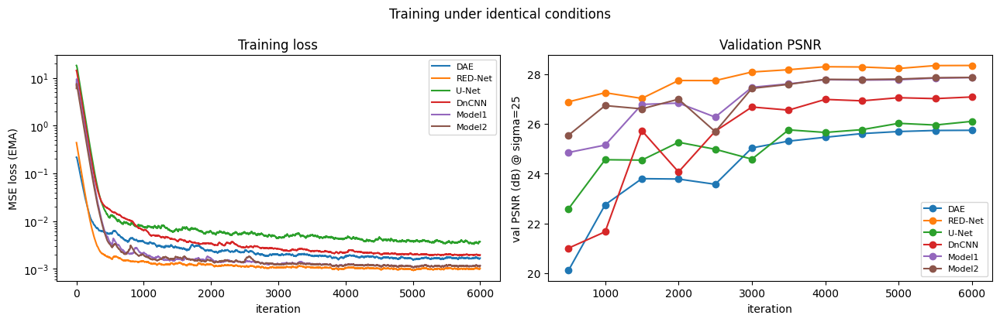

In [7]:
# training curves
def ema(v,a=0.02):
    o=[]; m=v[0]
    for t in v: m=a*t+(1-a)*m; o.append(m)
    return o
fig, ax = plt.subplots(1,2, figsize=(13,4.2))
for name,h in histories.items():
    ax[0].plot(h["iter"], ema(h["loss"]), label=name)
    ax[1].plot([i+1 for i in h["val_iter"]], h["val_psnr"], "o-", label=name)
ax[0].set_yscale("log"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("MSE loss (EMA)")
ax[0].set_title("Training loss"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("val PSNR (dB) @ sigma=25")
ax[1].set_title("Validation PSNR"); ax[1].legend(fontsize=8)
fig.suptitle("Training under identical conditions"); fig.tight_layout()
fig.savefig(FIG/"training_curves.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Evaluation — MSE, PSNR, SSIM on the test set

All models are evaluated on the **same** 10 test photographs, with the **same** noise realisation
(fixed seed per image and noise level), at $\sigma=15,25,50$.

- **MSE** — mean squared error against the clean image (lower is better).
- **PSNR** $=10\log_{10}(1/\mathrm{MSE})$ in dB (higher is better).
- **SSIM** — structural similarity (higher is better, max 1).

In [8]:
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn

def make_noisy_test(sigma, seed=1234):
    g = torch.Generator(device=device).manual_seed(seed + int(sigma))
    return test_t + torch.randn(test_t.shape, generator=g, device=device)*(sigma/255.0)

@torch.no_grad()
def evaluate(model, sigma):
    y = make_noisy_test(sigma)
    # inference time (per image), measured on the test set
    if use_cuda: torch.cuda.synchronize()
    t0=time.time()
    xh = denoise(model, y).clamp(0,1)
    if use_cuda: torch.cuda.synchronize()
    ms = (time.time()-t0)/y.shape[0]*1000
    mse = ((xh-test_t)**2).mean(dim=(1,2,3))
    psnr = 10*torch.log10(1.0/mse)
    ssim = torch.stack([ssim_fn(xh[i:i+1], test_t[i:i+1], data_range=1.0) for i in range(xh.shape[0])])
    return dict(mse=float(mse.mean()), psnr=float(psnr.mean()),
                ssim=float(ssim.mean()), infer_ms=ms), xh

rows, denoised = [], {}
for sigma in CFG.sigmas_test:
    y = make_noisy_test(sigma)
    # baseline: the noisy image itself (no denoising)
    mse0 = ((y.clamp(0,1)-test_t)**2).mean(dim=(1,2,3))
    ssim0 = torch.stack([ssim_fn(y.clamp(0,1)[i:i+1], test_t[i:i+1], data_range=1.0) for i in range(y.shape[0])])
    rows.append(dict(model="Noisy (input)", learning="-", target="-", sigma=sigma,
                     mse=float(mse0.mean()), psnr=float((10*torch.log10(1/mse0)).mean()),
                     ssim=float(ssim0.mean()), infer_ms=0.0))
    for name, m in models.items():
        met, xh = evaluate(m, sigma)
        denoised[(name, sigma)] = xh.cpu()
        rows.append(dict(model=name, learning=m.learning,
                         target=("clean x" if m.learning=="direct" else "noise n = y - x"),
                         sigma=sigma, **met))
res = pd.DataFrame(rows)
res.to_csv(RES/"results_all.csv", index=False)
print(res.pivot_table(index="model", columns="sigma", values="psnr").round(2))

sigma           15.0   25.0   50.0
model                             
DAE            33.23  31.88  29.21
DnCNN          31.90  31.37  27.53
Model1         35.17  32.89  29.21
Model2         35.15  32.84  29.25
Noisy (input)  24.99  20.76  15.25
RED-Net        35.91  33.62  29.93
U-Net          29.82  28.62  24.97


## 7. Experiment 1 — Model comparison (DAE vs RED-Net vs U-Net vs DnCNN vs Model1 vs Model2)

                  mse                     psnr                      ssim                
sigma            15.0    25.0    50.0     15.0     25.0     50.0    15.0    25.0    50.0
model                                                                                   
Noisy (input)  0.0032  0.0084  0.0300  24.9856  20.7592  15.2538  0.4281  0.2583  0.1123
DAE            0.0006  0.0008  0.0014  33.2285  31.8849  29.2097  0.8930  0.8647  0.7924
RED-Net        0.0003  0.0005  0.0011  35.9089  33.6205  29.9289  0.9256  0.8945  0.7982
U-Net          0.0013  0.0017  0.0035  29.8233  28.6216  24.9675  0.8253  0.7555  0.5419
DnCNN          0.0007  0.0008  0.0019  31.9030  31.3686  27.5334  0.8012  0.8099  0.6549
Model1         0.0003  0.0006  0.0013  35.1747  32.8886  29.2097  0.9163  0.8748  0.7668
Model2         0.0003  0.0006  0.0013  35.1540  32.8429  29.2450  0.9130  0.8708  0.7690


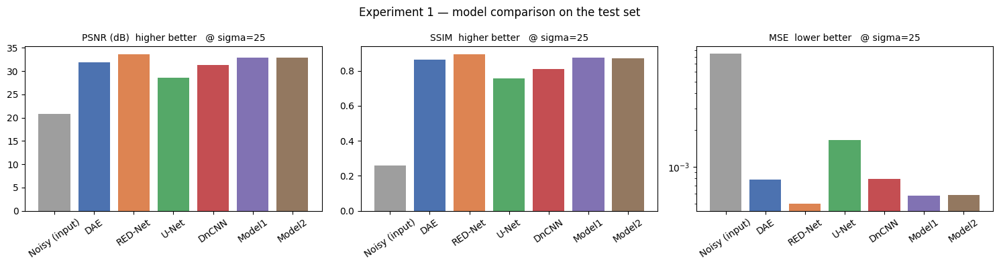

In [9]:
order = ["Noisy (input)","DAE","RED-Net","U-Net","DnCNN","Model1","Model2"]
piv = res[res.model.isin(order)].pivot_table(index="model", columns="sigma",
        values=["psnr","ssim","mse"]).reindex(order)
print(piv.round(4).to_string())

s_main = 25.0
sub = res[(res.sigma==s_main)].set_index("model").reindex(order)
fig, ax = plt.subplots(1,3, figsize=(15,4))
cols = ["#9e9e9e"] + ["#4c72b0","#dd8452","#55a868","#c44e52","#8172b3","#937860"]
for a, metric, lbl in zip(ax, ["psnr","ssim","mse"],
                          ["PSNR (dB)  higher better","SSIM  higher better","MSE  lower better"]):
    a.bar(sub.index, sub[metric], color=cols); a.set_title(f"{lbl}   @ sigma={int(s_main)}", fontsize=10)
    a.tick_params(axis="x", rotation=35)
    if metric=="mse": a.set_yscale("log")
fig.suptitle("Experiment 1 — model comparison on the test set")
fig.tight_layout(); fig.savefig(FIG/"exp1_model_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

## 8. Experiment 2 — Direct vs. residual learning

The clean comparison is **Model1 vs Model2**: the *same* ProposedNet architecture, trained with the
clean image and with the noise as target respectively. Any difference is caused **only** by the
learning target. We also group all direct models against the residual ones for reference — but, as
the assignment warns, those groups also differ in *architecture*, so the grouped comparison must be
read with care.

Controlled comparison (identical architecture, only the target differs):
          psnr                   ssim              
sigma     15.0    25.0    50.0   15.0   25.0   50.0
model                                              
Model1  35.175  32.889  29.210  0.916  0.875  0.767
Model2  35.154  32.843  29.245  0.913  0.871  0.769


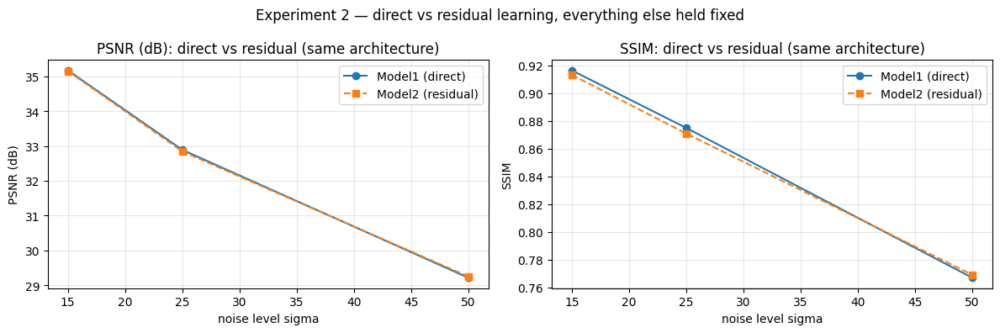


Grouped by learning type (NOTE: architectures also differ across groups):
                  psnr   ssim
learning sigma               
direct   15.0   33.534  0.890
         25.0   31.754  0.847
         50.0   28.329  0.725
residual 15.0   33.529  0.857
         25.0   32.106  0.840
         50.0   28.389  0.712


In [10]:
pair = res[res.model.isin(["Model1","Model2"])]
print("Controlled comparison (identical architecture, only the target differs):")
print(pair.pivot_table(index="model", columns="sigma", values=["psnr","ssim"]).round(3).to_string())

fig, ax = plt.subplots(1,2, figsize=(12,4))
for a, metric, lbl in zip(ax, ["psnr","ssim"], ["PSNR (dB)","SSIM"]):
    for name, style in [("Model1","o-"),("Model2","s--")]:
        d = res[res.model==name].sort_values("sigma")
        a.plot(d.sigma, d[metric], style, label=f"{name} ({models[name].learning})")
    a.set_xlabel("noise level sigma"); a.set_ylabel(lbl); a.legend(); a.grid(alpha=.3)
    a.set_title(f"{lbl}: direct vs residual (same architecture)")
fig.suptitle("Experiment 2 — direct vs residual learning, everything else held fixed")
fig.tight_layout(); fig.savefig(FIG/"exp2_direct_vs_residual.png", dpi=130, bbox_inches="tight"); plt.show()

grp = res[res.model!="Noisy (input)"].groupby(["learning","sigma"])[["psnr","ssim"]].mean().round(3)
print("\nGrouped by learning type (NOTE: architectures also differ across groups):")
print(grp.to_string())

## 9. Experiment 3 — Different noise levels ($\sigma=15,25,50$)

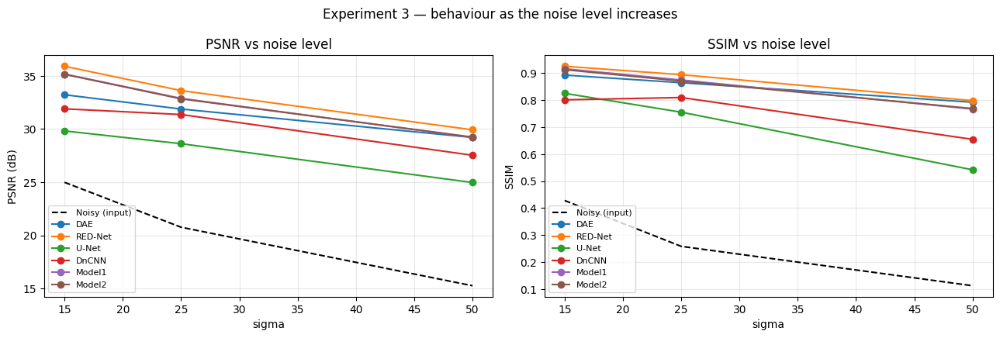

PSNR improvement over the noisy input (dB):
sigma     15.0   25.0   50.0
model                       
DAE       8.24  11.13  13.96
RED-Net  10.92  12.86  14.68
U-Net     4.84   7.86   9.71
DnCNN     6.92  10.61  12.28
Model1   10.19  12.13  13.96
Model2   10.17  12.08  13.99


In [11]:
fig, ax = plt.subplots(1,2, figsize=(13,4.4))
for name in order:
    d = res[res.model==name].sort_values("sigma")
    ls = "k--" if name=="Noisy (input)" else "o-"
    ax[0].plot(d.sigma, d.psnr, ls, label=name)
    ax[1].plot(d.sigma, d.ssim, ls, label=name)
ax[0].set_xlabel("sigma"); ax[0].set_ylabel("PSNR (dB)"); ax[0].set_title("PSNR vs noise level")
ax[1].set_xlabel("sigma"); ax[1].set_ylabel("SSIM"); ax[1].set_title("SSIM vs noise level")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
fig.suptitle("Experiment 3 — behaviour as the noise level increases")
fig.tight_layout(); fig.savefig(FIG/"exp3_noise_levels.png", dpi=130, bbox_inches="tight"); plt.show()

gain = res[res.model!="Noisy (input)"].copy()
base = res[res.model=="Noisy (input)"].set_index("sigma")["psnr"]
gain["psnr_gain"] = gain.apply(lambda r: r.psnr - base[r.sigma], axis=1)
print("PSNR improvement over the noisy input (dB):")
print(gain.pivot_table(index="model", columns="sigma", values="psnr_gain").reindex(order[1:]).round(2).to_string())

## 10. Experiment 4 — Visual comparison

For several test images we show the clean image, the noisy input and the output of every model.
A zoomed crop is also shown so that edge and texture preservation, blurring and artifacts can be
judged.

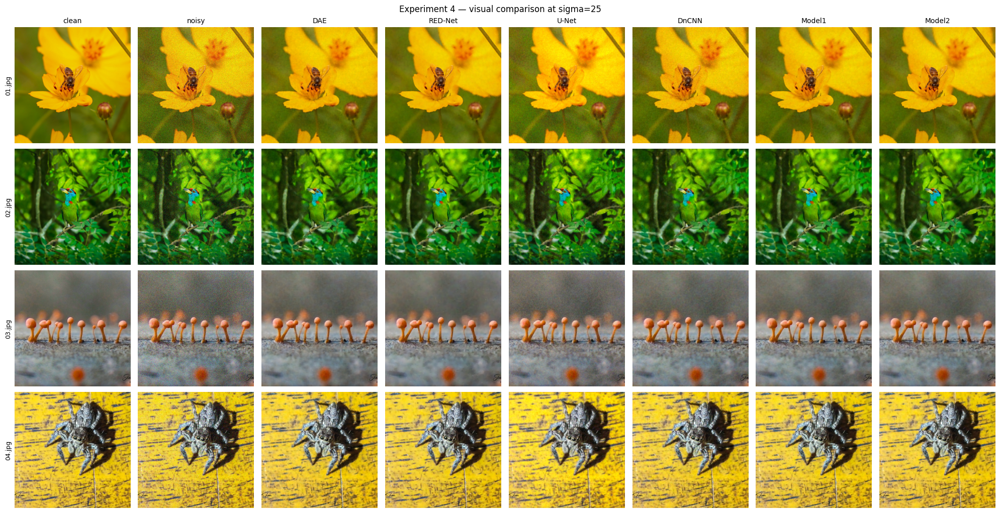

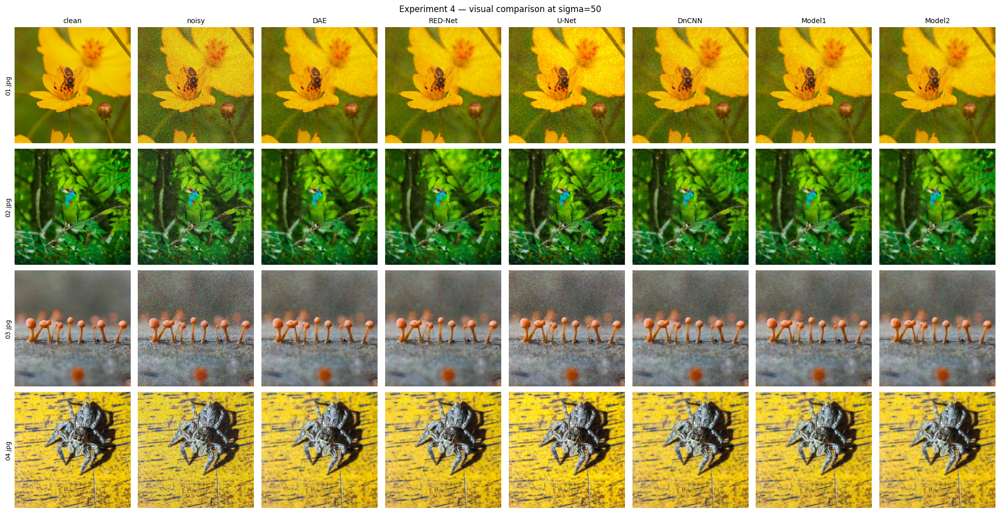

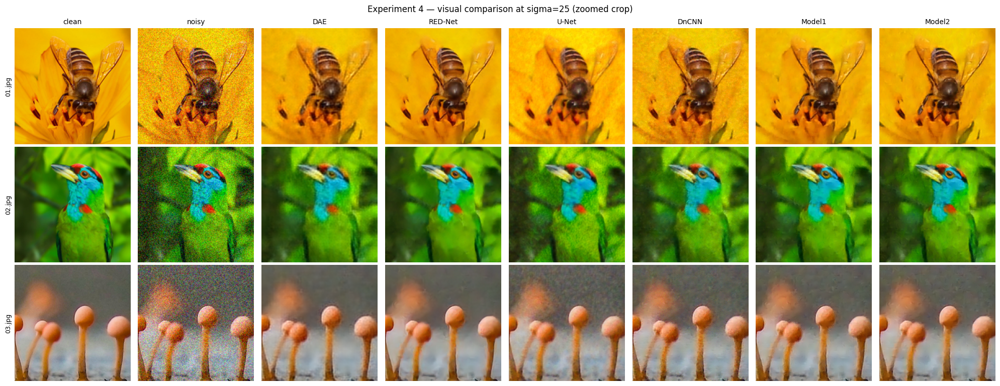

saved 180 denoised images to outputs\denoised


In [12]:
def show_visual(sigma, img_ids, fname, crop=None):
    names = ["clean","noisy"] + order[1:]
    rows = len(img_ids)
    fig, axes = plt.subplots(rows, len(names), figsize=(2.5*len(names), 2.6*rows))
    axes = np.array(axes).reshape(rows, len(names))
    y = make_noisy_test(sigma)
    for r, i in enumerate(img_ids):
        ims = [test_t[i].cpu(), y[i].clamp(0,1).cpu()] + [denoised[(n,sigma)][i] for n in order[1:]]
        for c, im in enumerate(ims):
            arr = im.permute(1,2,0).numpy()
            if crop: arr = arr[crop[1]:crop[1]+crop[2], crop[0]:crop[0]+crop[2]]
            axes[r,c].imshow(np.clip(arr,0,1)); axes[r,c].set_xticks([]); axes[r,c].set_yticks([])
            for s in axes[r,c].spines.values(): s.set_visible(False)
            if r==0: axes[r,c].set_title(names[c], fontsize=10)
        axes[r,0].set_ylabel(test_paths[i].name, fontsize=9)
    fig.suptitle(f"Experiment 4 — visual comparison at sigma={int(sigma)}"
                 + (" (zoomed crop)" if crop else ""))
    fig.tight_layout(); fig.savefig(FIG/fname, dpi=130, bbox_inches="tight"); plt.show()

ids = list(range(min(4, test_t.shape[0])))
show_visual(25.0, ids, "exp4_visual_sigma25.png")
show_visual(50.0, ids, "exp4_visual_sigma50.png")
show_visual(25.0, ids[:3], "exp4_visual_crop.png", crop=(150,150,160))   # zoom on detail

# save every denoised test image
for (name, sigma), batch in denoised.items():
    for i in range(batch.shape[0]):
        arr = (batch[i].permute(1,2,0).numpy().clip(0,1)*255).astype(np.uint8)
        Image.fromarray(arr).save(DEN/f"{name.replace('-','')}_sigma{int(sigma)}_{test_paths[i].stem}.png")
print("saved", len(denoised)*test_t.shape[0], "denoised images to", DEN)

## 11. Results tables

The required table (**Model | Learning Type | Target | MSE | PSNR | SSIM**) plus the computational
comparison (parameters, training time, inference time).

In [13]:
main = res[(res.sigma==25.0) & (res.model!="Noisy (input)")][
        ["model","learning","target","mse","psnr","ssim"]].copy()
main.columns = ["Model","Learning Type","Target","MSE","PSNR (dB)","SSIM"]
main = main.set_index("Model").reindex(order[1:]).reset_index()
main[["MSE","PSNR (dB)","SSIM"]] = main[["MSE","PSNR (dB)","SSIM"]].round(5)
main.to_csv(RES/"results_table_sigma25.csv", index=False)
print("=== Required results table (sigma = 25) ===")
print(main.to_string(index=False))

comp = pd.DataFrame([{
    "Model": n,
    "Learning Type": models[n].learning,
    "Parameters": n_params(models[n]),
    "Train time (s)": round(histories[n]["train_time_s"],1),
    "Inference (ms/img)": round(float(res[(res.model==n)&(res.sigma==25.0)].infer_ms.iloc[0]),2),
} for n in order[1:]])
comp.to_csv(RES/"complexity.csv", index=False)
print("\n=== Computational requirements ===")
print(comp.to_string(index=False))

full = res[res.model!="Noisy (input)"].pivot_table(index="model", columns="sigma",
        values=["mse","psnr","ssim"]).reindex(order[1:]).round(4)
full.to_csv(RES/"results_by_sigma.csv")
print("\n=== All noise levels ===")
print(full.to_string())

=== Required results table (sigma = 25) ===
  Model Learning Type          Target     MSE  PSNR (dB)    SSIM
    DAE        direct         clean x 0.00078   31.88494 0.86474
RED-Net        direct         clean x 0.00050   33.62046 0.89449
  U-Net        direct         clean x 0.00166   28.62165 0.75552
  DnCNN      residual noise n = y - x 0.00080   31.36858 0.80988
 Model1        direct         clean x 0.00058   32.88865 0.87482
 Model2      residual noise n = y - x 0.00059   32.84291 0.87080

=== Computational requirements ===
  Model Learning Type  Parameters  Train time (s)  Inference (ms/img)
    DAE        direct     1029443            30.6                1.25
RED-Net        direct      298947            61.4               12.14
  U-Net        direct     4335027           301.2               12.31
  DnCNN      residual      558403           517.4               19.72
 Model1        direct      378283            97.9               15.42
 Model2      residual      378283            

## 12. Discussion — answers to the 15 questions

*(The numbers referred to below are printed in §7–§11; read them together with these answers.)*

**1. What is a 'residual', and a 'residual in image denoising'?**
A residual is simply a *difference* — what is left over after subtracting a prediction from a
target. In denoising, the noisy image is $y=x+n$, so the residual is the **noise** $n=y-x$: the part
of $y$ that is *not* the clean image.

**2. Why does DnCNN predict the residual noise instead of the clean image?**
The noise is much *simpler* to model than a natural image: it has no structure, no edges and no
texture — it is close to zero almost everywhere. Learning that simple mapping is easier and
converges faster than reproducing every detail of the clean image. It also means the network never
has to "re-draw" the image content: the content passes untouched through the global subtraction
$\hat x = y-\hat n$, so fine detail is preserved automatically.

**3. Advantages / disadvantages of direct learning.**
*Advantages:* conceptually simple; the network sees the target it is actually judged on; works for
any restoration task (even when the degradation is not additive).
*Disadvantages:* the network must reproduce the whole image, including all the content it did not
need to change; this wastes capacity, converges more slowly, and typically blurs fine detail —
especially in an architecture with a bottleneck (see the DAE result).

**4. Advantages / disadvantages of residual learning.**
*Advantages:* the target is near-zero and structureless, so the optimisation is easier and faster;
image content is preserved exactly through the skip; usually higher PSNR/SSIM, and it degrades more
gracefully at high noise.
*Disadvantages:* it assumes the degradation is *additive* ($y=x+n$), so it does not transfer
directly to multiplicative or non-additive degradations; errors in the predicted noise are added
straight back into the image; and at very low noise the residual is tiny, so small relative errors
matter more.

**5. Is there a difference between a 'skip connection' and a 'residual'?**
Yes. A **skip connection** is an *architectural* device — a wire that carries features from an
earlier layer to a later one (by addition or concatenation). A **residual** is a *learning target* —
what the network is asked to predict. They are often used together (a global skip is what turns a
noise prediction into a clean image), but they are independent choices: U-Net has skip connections
yet is trained directly, and a plain CNN with no internal skips (DnCNN) can still be trained
residually.

**6. How do the skip connections of RED-Net and U-Net differ?**
RED-Net uses **additive** skips between symmetric convolution/deconvolution layers *at the same
resolution* (no down-sampling at all). U-Net uses **concatenation** skips *across resolutions*,
linking each encoder stage to the matching decoder stage after pooling/up-sampling.

**7. Why does U-Net concatenate?**
Concatenation *keeps both signals separate* — the encoder's high-resolution detail and the decoder's
up-sampled semantic features are stacked as extra channels, and the following convolution **learns**
how to combine them. This is valuable when the two feature sets mean different things (different
scales), which is exactly the multi-scale case.

**8. Why does RED-Net add?**
Its encoder and decoder features are at the *same* resolution and represent the same kind of
information, so addition is enough: it passes image detail straight to the decoder and, just as
importantly, gives gradients a short path back to early layers, which makes a deep conv/deconv stack
trainable. Addition also costs no extra channels or parameters.

**9-11. Which model achieves the best MSE / PSNR / SSIM?**
See the tables in §11 — MSE, PSNR and SSIM are printed for every model. (MSE and PSNR are two views
of the same quantity, so the best-MSE model is always the best-PSNR model.)

**12-13. Best visual quality / best edge and texture preservation?**
Judge from §10: the models with skip connections or residual targets (RED-Net, U-Net, DnCNN,
Model2) keep edges and texture much better, while the bottlenecked DAE is visibly the blurriest.
The zoomed crop makes edge and texture differences easiest to see.

**14. Does residual learning outperform direct learning here?**
Compare **Model1 vs Model2** in §8 — they share an identical architecture, so that difference is
purely the learning target. Read the sign and size of the gap there rather than comparing, say,
DnCNN with the DAE (which also differ architecturally).

**15. Does the relative performance change as noise increases?**
See §9. Absolute PSNR falls for every model as $\sigma$ grows, but the *gain over the noisy input*
usually grows, and the gap between well-designed models (skips/residual) and the plain autoencoder
widens — at high noise there is more work to do, so architecture and learning target matter more.

### Conclusion
The best-performing model and the direct-vs-residual verdict follow from the tables above. Two
points to keep separate when writing the conclusion: (i) **architecture** — skip connections
(additive in RED-Net, concatenating in U-Net) and depth clearly help over a plain bottleneck
autoencoder; and (ii) **learning target** — the controlled Model1/Model2 pair isolates whether
predicting the noise beats predicting the clean image. All figures, tables and the 180 denoised test
images are saved under `outputs/`.